<a href="https://colab.research.google.com/github/QuantumGuy99/SETI-/blob/main/SETI_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q blimpy hdf5plugin turbo_seti setigen
!wget -q -nc http://blpd0.ssl.berkeley.edu/Voyager_data/Voyager1.single_coarse.fine_res.h5

import hdf5plugin
import numpy as np
import matplotlib.pyplot as plt
from blimpy import Waterfall
import setigen as stg
from astropy import units as u

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pyiceberg 0.12.0 requires pyparsing>=3.1.0, but you have pyparsing 2.4.7 which is incompatible.
rasterio 1.5.2 requires pyparsing>=3.0, but you have pyparsing 2.4.7 which is incompatible.
pydot 4.0.1 requires pyparsing>=3.1.0, but you have pyparsing 2.4.7 which is incompatible.
httplib2 0.32.1 requires pyparsing<4,>=3.1, but you have pyparsing 2.4.7 which is incompatible.


/usr/local/lib/python3.13/dist-packages/blimpy/__init__.py:21: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


(3000, 32, 256) signals: 1500 noise only: 1500


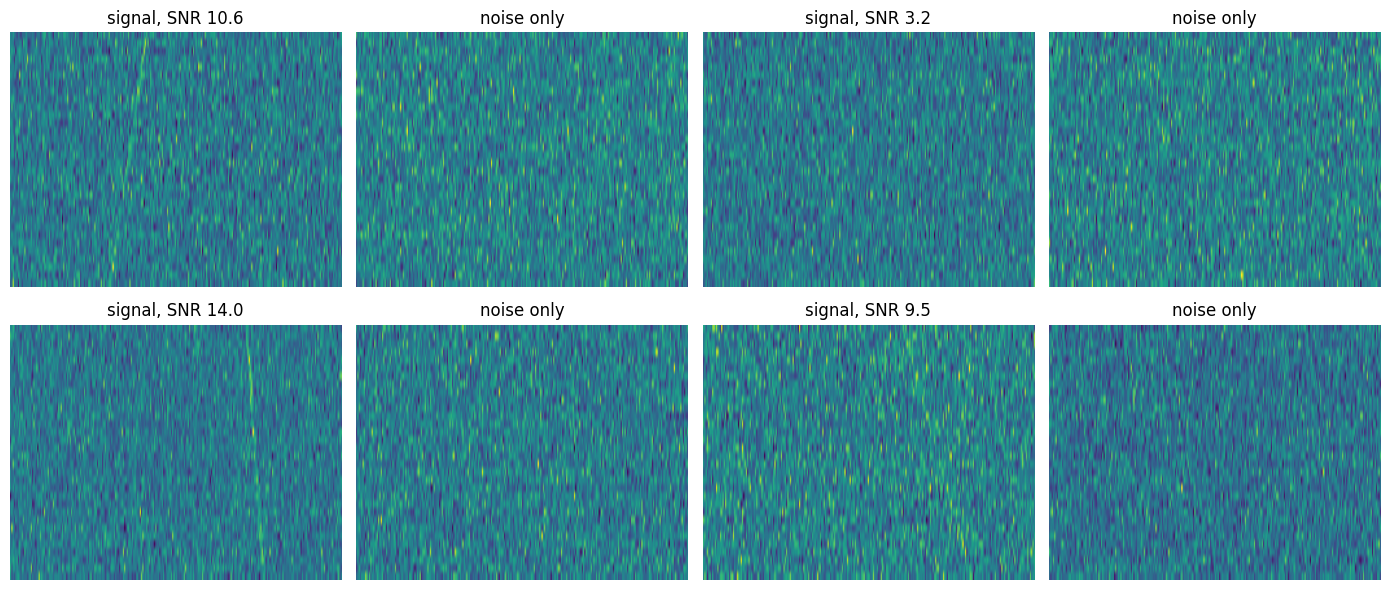

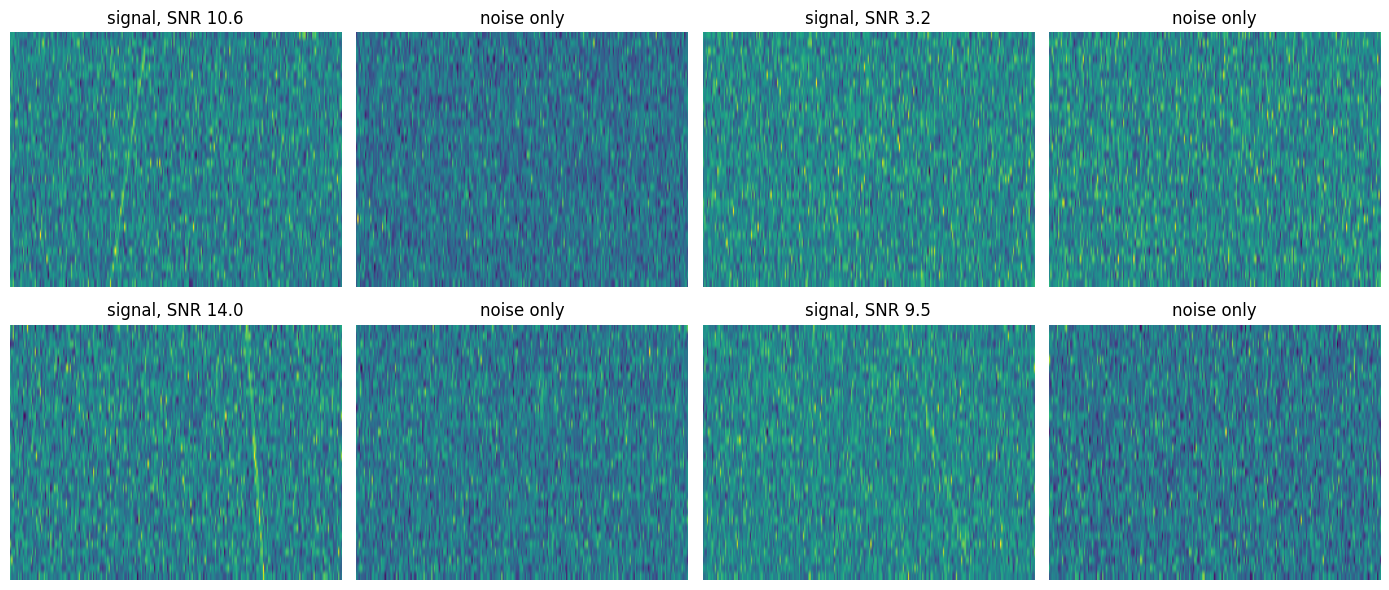

In [ ]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import setigen as stg
from astropy import units as u

rng = np.random.default_rng(0)

def make_example(has_signal):
    frame = stg.Frame(fchans=256*u.pixel, tchans=32*u.pixel,
                      df=2.7939677238*u.Hz, dt=18.253611*u.s, fch1=8419.0*u.MHz)
    frame.add_noise(x_mean=10, noise_type='chi2')
    snr = 0.0
    if has_signal:
        snr = rng.uniform(3, 15)
        drift = rng.uniform(-0.3, 0.3)       # Hz/s, keeps the signal inside the frame
        start = int(rng.integers(70, 186))   # starting channel
        frame.add_signal(stg.constant_path(f_start=frame.get_frequency(index=start),
                                           drift_rate=drift*u.Hz/u.s),
                         stg.constant_t_profile(level=frame.get_intensity(snr=snr)),
                         stg.gaussian_f_profile(width=5*u.Hz),
                         stg.constant_bp_profile(level=1))
    data = frame.get_data()
    data = (data - data.mean()) / data.std()   # normalize
    return data.astype(np.float32), snr

N = 3000
X, y, snrs = [], [], []
for i in range(N):
    has_signal = i % 2 == 0                    # half signal, half noise
    d, s = make_example(has_signal)
    X.append(d); y.append(int(has_signal)); snrs.append(s)

X = np.array(X); y = np.array(y); snrs = np.array(snrs)
print(X.shape, 'signals:', y.sum(), 'noise only:', (y == 0).sum())

# Look at a few examples
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, i in zip(axes.flat, range(8)):
    ax.imshow(X[i], aspect='auto')
    ax.set_title(f'signal, SNR {snrs[i]:.1f}' if y[i] else 'noise only')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split

torch.manual_seed(0)

# Hold out 20% of the data that the model never trains on
idx = np.arange(len(X))
tr, te = train_test_split(idx, test_size=0.2, random_state=0, stratify=y)

Xt = torch.tensor(X).unsqueeze(1)           # shape (N, 1, 32, 256)
yt = torch.tensor(y, dtype=torch.float32)

# A small convolutional network; the final max-pool asks
# "is there a line-like feature anywhere in this image?"
model = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveMaxPool2d(1),
    nn.Flatten(), nn.Linear(64, 1)
)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.BCEWithLogitsLoss()

def predict(idxs):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(Xt[idxs]).squeeze(1)).numpy()

for epoch in range(15):
    model.train()
    perm = np.random.permutation(tr)
    for i in range(0, len(perm), 64):
        b = perm[i:i+64]
        opt.zero_grad()
        loss = loss_fn(model(Xt[b]).squeeze(1), yt[b])
        loss.backward()
        opt.step()
    acc = ((predict(te) > 0.5) == y[te]).mean()
    print(f'epoch {epoch+1}: loss {loss.item():.3f}, test accuracy {acc:.3f}')

# Where does it succeed and fail?
pred = predict(te) > 0.5
print('\nfalse alarm rate on noise-only examples:', round(pred[y[te] == 0].mean(), 3))
for lo, hi in [(3, 6), (6, 9), (9, 12), (12, 15)]:
    m = (y[te] == 1) & (snrs[te] >= lo) & (snrs[te] < hi)
    print(f'injected SNR {lo}-{hi}: detected {pred[m].mean():.2f} of {m.sum()} signals')

epoch 1: loss 0.680, test accuracy 0.500
epoch 2: loss 0.626, test accuracy 0.697
epoch 3: loss 0.564, test accuracy 0.793
epoch 4: loss 0.452, test accuracy 0.823
epoch 5: loss 0.524, test accuracy 0.835
epoch 6: loss 0.376, test accuracy 0.832
epoch 7: loss 0.368, test accuracy 0.805
epoch 8: loss 0.589, test accuracy 0.830
epoch 9: loss 0.290, test accuracy 0.832
epoch 10: loss 0.273, test accuracy 0.842
epoch 11: loss 0.436, test accuracy 0.838
epoch 12: loss 0.200, test accuracy 0.852
epoch 13: loss 0.240, test accuracy 0.852
epoch 14: loss 0.356, test accuracy 0.853
epoch 15: loss 0.259, test accuracy 0.850

false alarm rate on noise-only examples: 0.087
injected SNR 3-6: detected 0.29 of 62 signals
injected SNR 6-9: detected 0.76 of 83 signals
injected SNR 9-12: detected 1.00 of 70 signals
injected SNR 12-15: detected 1.00 of 85 signals
